# Minimax và Alpha-Beta - Caro 11×11

**Người phụ trách:** Lê Ngọc Phúc · **Tài liệu phân công:** `docs/Ngoc-Phuc.md`

| Giai đoạn | Phần notebook | Trạng thái |
| :--- | :--- | :--- |
| 1 - Trạng thái tìm kiếm và hàm lượng giá | 1-4 | Đang thực hiện (notebook này) |
| 2 - Minimax, Alpha-Beta, Iterative Deepening | 5-6 | Chưa thực hiện |
| 3 - Đối chứng cắt tỉa, khảo sát độ sâu, thi đấu | 7-10 | Chưa thực hiện |

Notebook chỉ tổ chức thí nghiệm; toàn bộ thuật toán được import từ `agents/minimax_agent.py`.
Chạy lại bằng **Restart Kernel → Run All**.

## 1. Câu hỏi nghiên cứu và phạm vi

**Câu hỏi chính (trả lời ở Giai đoạn 2-3):** Alpha-Beta giúp giảm bao nhiêu phần trăm số nút duyệt
và thời gian tính toán so với Minimax thuần khi giữ nguyên chất lượng nước đi ở cùng độ sâu?

Để câu hỏi này có ý nghĩa, hai biến thể phải dùng **chung** một tầng trạng thái, một hàm lượng giá
và một tập nước ứng viên. Giai đoạn 1 xây dựng và kiểm chứng phần nền tảng chung đó:

1. **Trạng thái tìm kiếm** (`SearchState`): chuyển trạng thái và phát hiện kết thúc phải khớp Game Engine;
   duyệt nước con không được làm thay đổi trạng thái cha.
2. **Hàm lượng giá** (`evaluate`): thống nhất góc nhìn, điểm terminal luôn vượt trội điểm heuristic.

**Ngoài phạm vi Giai đoạn 1:** thuật toán tìm kiếm, cắt tỉa, chế độ `time`, thi đấu.

In [1]:
from pathlib import Path
import os

# Chuyển về thư mục Caro để import module chung từ vị trí notebook.
if Path.cwd().name == 'notebooks' and (Path.cwd().parent / 'core').is_dir():
    os.chdir(Path.cwd().parent)
if not (Path.cwd() / 'core' / 'game_engine.py').is_file():
    raise RuntimeError('Hãy mở notebook từ thư mục caro-11x11 hoặc notebooks')

import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from agents.minimax_agent import (WIN_SCORE, WINDOW_WEIGHTS, SearchState, evaluate,
                                  heuristic_bound, heuristic_score, terminal_score,
                                  window_counts)
from agents.random_agent import RandomAgent
from config.game_config import BOARD_SIZE, WIN_LENGTH
from config.search_budget import SearchBudget
from core import CaroGame

X, O = 1, -1
print('Đã import module agents.minimax_agent từ', Path('agents/minimax_agent.py').resolve())

Đã import module agents.minimax_agent từ D:\TTNT_NC\AdvancedAI-Repo\caro-11x11\agents\minimax_agent.py


## 2. Môi trường và cấu hình

Toàn bộ cấu hình tập trung ở cell dưới. Các mục Giai đoạn 2 (độ sâu, thứ tự xét nước) được ghi trước
để cố định, nhưng **chưa được sử dụng** trong notebook này.

In [ ]:
CONFIG = {
    'Kích thước bàn': BOARD_SIZE,
    'Số quân liên tiếp để thắng': WIN_LENGTH,
    'Bán kính ứng viên (candidate_actions)': 2,
    'Trọng số cửa sổ theo số quân 0..5': WINDOW_WEIGHTS,
    'Điểm terminal (WIN_SCORE)': WIN_SCORE,
    'Cận trên |heuristic|': heuristic_bound(),
    'Độ sâu fixed dự kiến (Giai đoạn 2)': SearchBudget().depth,
    'Giới hạn thời gian chế độ time (Giai đoạn 2)': SearchBudget(mode='time').time_limit_s,
    'Thứ tự xét nước (Giai đoạn 2)': 'theo hàng rồi cột của candidate_actions - chưa sắp xếp',
    'Seed ván ngẫu nhiên (Phần 3)': list(range(20)),
}
HARDWARE = {
    'Hệ điều hành': platform.platform(),
    'CPU': platform.processor() or 'không xác định',
    'Số luồng CPU': os.cpu_count(),
    'Python': sys.version.split()[0],
    'NumPy': np.__version__,
}
display(pd.DataFrame({'Giá trị': {k: str(v) for k, v in CONFIG.items()}}))
display(pd.DataFrame({'Giá trị': {k: str(v) for k, v in HARDWARE.items()}}))

,Giá trị
Kích thước bàn,11
Số quân liên tiếp để thắng,5
Bán kính ứng viên (candidate_actions),2
Trọng số cửa sổ theo số quân 0..5,"(0, 1, 10, 100, 1000, 0)"
Điểm terminal (WIN_SCORE),10000000
Cận trên |heuristic|,252000
Độ sâu fixed dự kiến (Giai đoạn 2),2
Giới hạn thời gian chế độ time (Giai đoạn 2),2.0
Thứ tự xét nước (Giai đoạn 2),theo hàng rồi cột của candidate_actions — chưa...
Seed ván ngẫu nhiên (Phần 3),"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."


,Giá trị
Hệ điều hành,Windows-10-10.0.26200-SP0
CPU,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
Số luồng CPU,16
Python,3.11.9
NumPy,2.4.6


**Nhận xét:** Phần cứng chỉ ảnh hưởng thời gian chạy ở Giai đoạn 2-3; mọi kết quả ở Giai đoạn 1 là tất định
(không phụ thuộc máy). Seed chỉ dùng để sinh ván ngẫu nhiên phục vụ đối chiếu với engine.

## 3. Kiểm chứng trạng thái tìm kiếm

**Thiết kế:** `SearchState` giữ bản sao bàn cờ riêng; `apply(action)` trả về **đối tượng mới**,
nên trạng thái cha bất biến. Phát hiện thắng chỉ xét 4 đường qua nước vừa đi (giống `CaroGame.check_winner`);
hòa khi bàn đầy. Khi ván kết thúc, `current_player` giữ người vừa đi nước cuối - đúng quy ước engine.

**Thí nghiệm:** chạy cùng một chuỗi nước trên engine và trên `SearchState`, so sánh **sau từng nước**
5 trường: bàn cờ, người đến lượt, nước cuối, số nước, kết quả.

**Kỳ vọng:** khớp 100% ở mọi bước, cho cả X và O, 4 hướng, chuỗi 5 và chuỗi 6, ván hòa và ván ngẫu nhiên.

In [3]:
DIRECTIONS = {'ngang': ((0, 1), (5, 1)), 'dọc': ((1, 0), (1, 5)),
              'chéo chính': ((1, 1), (1, 1)), 'chéo phụ': ((1, -1), (1, 9))}

def interleave(x_moves, o_moves):
    moves = []
    for i, x in enumerate(x_moves):
        moves.append(x)
        if i < len(o_moves):
            moves.append(o_moves[i])
    return moves

def winning_sequence(winner, direction, length):
    # Chuỗi 6: đi ô thứ 4 cuối cùng để nối hai đoạn 3 + 2 thành 6.
    (dr, dc), (r0, c0) = DIRECTIONS[direction]
    line = [(r0 + k * dr, c0 + k * dc) for k in range(length)]
    if length == 6:
        line = line[:3] + line[4:] + [line[3]]
    filler = [(r, c) for r in range(0, 11, 2) for c in range(0, 11, 2) if (r, c) not in line]
    return interleave(line, filler[:length - 1]) if winner == X else interleave(filler[:length], line)

def draw_sequence():
    x_cells = [(r, c) for r in range(11) for c in range(11) if (c + r // 2) % 2 == 0]
    o_cells = [(r, c) for r in range(11) for c in range(11) if (c + r // 2) % 2 == 1]
    return interleave(x_cells, o_cells)

def random_sequence(seed):
    game, agents = CaroGame(), {X: RandomAgent(seed), O: RandomAgent(seed + 100)}
    moves = []
    while not game.is_terminal():
        action = agents[game.current_player].choose_action(game.board, game.current_player)
        game.step(action)
        moves.append(action)
    return moves

def compare_with_engine(moves):
    game, state = CaroGame(), SearchState.initial()
    mismatches = 0
    for move in moves:
        game.step(move)
        state = state.apply(move)
        same = (np.array_equal(state.board, game.board)
                and state.current_player == game.current_player
                and state.last_action == game.last_action
                and state.move_count == game.move_count
                and state.result() == game.result())
        mismatches += not same
    return game, state, mismatches

cases = {f'{"X" if w == X else "O"} thắng, {d}, chuỗi {n}': winning_sequence(w, d, n)
         for w in (X, O) for d in DIRECTIONS for n in (5, 6)}
cases['Hòa, bàn đầy 61 X / 60 O'] = draw_sequence()
cases.update({f'Ngẫu nhiên seed {s}': random_sequence(s) for s in CONFIG['Seed ván ngẫu nhiên (Phần 3)']})

label = {None: 'đang chơi', 1: 'X thắng', -1: 'O thắng', 0: 'hòa'}
rows = []
for name, moves in cases.items():
    game, state, mismatches = compare_with_engine(moves)
    rows.append({'Tình huống': name, 'Số nước': len(moves), 'Engine': label[game.result()],
                 'SearchState': label[state.result()], 'Số bước lệch': mismatches})
table = pd.DataFrame(rows)
display(table)
print(f'Tổng: {len(table)} chuỗi, {table["Số nước"].sum()} bước so sánh, '
      f'{table["Số bước lệch"].sum()} bước lệch.')

,Tình huống,Số nước,Engine,SearchState,Số bước lệch
0,"X thắng, ngang, chuỗi 5",9,X thắng,X thắng,0
1,"X thắng, ngang, chuỗi 6",11,X thắng,X thắng,0
2,"X thắng, dọc, chuỗi 5",9,X thắng,X thắng,0
3,"X thắng, dọc, chuỗi 6",11,X thắng,X thắng,0
4,"X thắng, chéo chính, chuỗi 5",9,X thắng,X thắng,0
5,"X thắng, chéo chính, chuỗi 6",11,X thắng,X thắng,0
6,"X thắng, chéo phụ, chuỗi 5",9,X thắng,X thắng,0
7,"X thắng, chéo phụ, chuỗi 6",11,X thắng,X thắng,0
8,"O thắng, ngang, chuỗi 5",10,O thắng,O thắng,0
9,"O thắng, ngang, chuỗi 6",12,O thắng,O thắng,0


Tổng: 37 chuỗi, 1768 bước so sánh, 0 bước lệch.


In [4]:
# Tính độc lập trạng thái: duyệt mọi nước con (và 5 nước cháu mỗi con) rồi kiểm tra cha.
game = CaroGame()
for move in random_sequence(7)[:12]:
    game.step(move)
input_board = game.board.copy()
parent = SearchState(input_board, game.current_player)
snapshot = (parent.board.copy(), parent.current_player, parent.last_action, parent.move_count, parent.result())

n_children = 0
for action in parent.candidates():
    child = parent.apply(action)
    n_children += 1
    for grandchild_action in child.candidates()[:5]:
        child.apply(grandchild_action)
        n_children += 1

unchanged = (np.array_equal(parent.board, snapshot[0])
             and (parent.current_player, parent.last_action, parent.move_count, parent.result()) == snapshot[1:])
print(f'Đã sinh {n_children} trạng thái con/cháu từ {len(parent.candidates())} ứng viên.')
print('Trạng thái cha giữ nguyên:', unchanged)
print('Mảng board đầu vào giữ nguyên:', np.array_equal(input_board, game.board))

Đã sinh 468 trạng thái con/cháu từ 78 ứng viên.
Trạng thái cha giữ nguyên: True
Mảng board đầu vào giữ nguyên: True


**Nhận xét:** Bảng trên cho thấy số bước lệch của từng chuỗi; tổng số bước lệch ở dòng in cuối là
kết quả đối chiếu thực tế. Các chuỗi chuỗi-6 xác nhận luật freestyle (dài hơn 5 vẫn thắng) và chuỗi hòa
xác nhận phát hiện bàn đầy. Cell thứ hai xác nhận việc duyệt cây không làm biến dạng trạng thái cha.
Các kiểm tra này cũng có trong `tests/test_minimax_agent.py`; notebook chỉ minh họa, không thay unit test.

## 4. Giải thích hàm lượng giá

### 4.1 Quy ước góc nhìn và thang điểm

`evaluate(state, perspective)` trả điểm **theo góc nhìn bên `perspective`**: dương là có lợi cho bên đó.
Đổi góc nhìn chỉ đổi dấu: `evaluate(s, X) == -evaluate(s, O)`.

| Loại trạng thái | Điểm theo góc nhìn `perspective` |
| :--- | :--- |
| Terminal - `perspective` thắng | `+WIN_SCORE` = +10 000 000 |
| Terminal - `perspective` thua | `−WIN_SCORE` = −10 000 000 |
| Terminal - hòa | 0 |
| Chưa kết thúc | heuristic, luôn nằm trong `[−heuristic_bound, +heuristic_bound]` |

Terminal và heuristic tách thành hai hàm (`terminal_score`, `heuristic_score`); `evaluate` kiểm tra terminal trước.

In [ ]:
bound = heuristic_bound()
print(f'Số cửa sổ 5 ô trên bàn {BOARD_SIZE}×{BOARD_SIZE}: {bound // max(WINDOW_WEIGHTS)}')
print(f'Cận trên |heuristic| = số cửa sổ × trọng số lớn nhất = {bound:,}')
print(f'WIN_SCORE = {WIN_SCORE:,} - gấp {WIN_SCORE / bound:.1f} lần cận trên heuristic')
print('terminal_score: X thắng nhìn từ X =', terminal_score(1, X), '| từ O =', terminal_score(1, O),
      '| hòa =', terminal_score(0, X))

Số cửa sổ 5 ô trên bàn 11×11: 252
Cận trên |heuristic| = số cửa sổ × trọng số lớn nhất = 252,000
WIN_SCORE = 10,000,000 — gấp 39.7 lần cận trên heuristic
terminal_score: X thắng nhìn từ X = 10000000 | từ O = -10000000 | hòa = 0


### 4.2 Thành phần heuristic: cửa sổ 5 ô

Mỗi **cửa sổ** là một đoạn 5 ô liên tiếp theo một trong 4 hướng (252 cửa sổ trên bàn 11×11).
Một cửa sổ **còn sống** với X nếu không chứa quân O - X vẫn có thể lấp đủ cửa sổ đó để thắng.

$$h(\text{board}, p) = p \cdot \Big(\sum_{w\ \text{sống với X}} W[\#X(w)] - \sum_{w\ \text{sống với O}} W[\#O(w)]\Big)$$

với trọng số `W = (0, 1, 10, 100, 1000, 0)` theo số quân trong cửa sổ.

**Lý do chọn:**
- Cửa sổ bị đối thủ chiếm một ô không bao giờ thành chuỗi thắng → không tính cho ai. Đây là cách tự nhiên
  để phân biệt chuỗi **mở** (nhiều cửa sổ sống) với chuỗi **bị chặn** (ít cửa sổ sống).
- Mỗi quân thêm vào cửa sổ nhân điểm lên 10: một cửa sổ còn thiếu 1 quân (gần thắng) nặng hơn
  vài cửa sổ yếu hơn cộng lại.
- Cửa sổ đủ 5 quân là terminal → trọng số 0, giao cho `terminal_score`.
- Cửa sổ nhận cả chuỗi có khoảng trống (ví dụ `X X . X X` là cửa sổ 4 quân), điều mà đếm quân liền kề bỏ sót.

Hình dưới đếm số cửa sổ đi qua từng ô = điểm của **một quân đơn lẻ** đặt tại ô đó (trọng số 1 quân = 1).

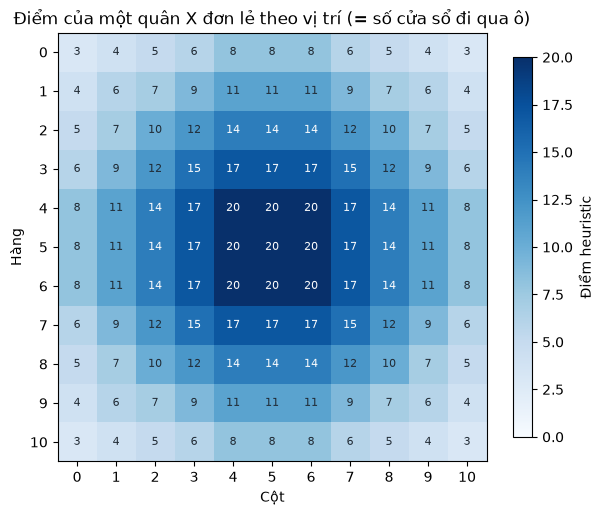

Tâm: 20 | góc: 3 | giữa mép: 8


In [6]:
coverage = np.zeros((BOARD_SIZE, BOARD_SIZE), dtype=int)
for r in range(BOARD_SIZE):
    for c in range(BOARD_SIZE):
        board = np.zeros((BOARD_SIZE, BOARD_SIZE), dtype=np.int8)
        board[r, c] = X
        coverage[r, c] = heuristic_score(board, X)

fig, ax = plt.subplots(figsize=(6.2, 5.4))
image = ax.imshow(coverage, cmap='Blues', vmin=0)
for r in range(BOARD_SIZE):
    for c in range(BOARD_SIZE):
        ax.text(c, r, coverage[r, c], ha='center', va='center', fontsize=8,
                color='white' if coverage[r, c] > coverage.max() * 0.6 else '#1f2933')
ax.set_xticks(range(BOARD_SIZE))
ax.set_yticks(range(BOARD_SIZE))
ax.set_xlabel('Cột')
ax.set_ylabel('Hàng')
ax.set_title('Điểm của một quân X đơn lẻ theo vị trí (= số cửa sổ đi qua ô)')
fig.colorbar(image, ax=ax, shrink=0.8, label='Điểm heuristic')
plt.tight_layout()
plt.show()
print('Tâm:', coverage[5, 5], '| góc:', coverage[0, 0], '| giữa mép:', coverage[0, 5])

**Nhận xét:** Không cần thêm bảng điểm vị trí riêng - trọng số cửa sổ tự tạo ưu tiên trung tâm
(ô tâm nằm trong 20 cửa sổ, góc chỉ 3), vì quân ở trung tâm có nhiều hướng phát triển hơn.
Cả vùng 3×3 quanh tâm (hàng/cột 4–6) cùng đạt 20: trên bàn 11×11, các ô này đều đủ chỗ cho cả 5 vị trí
cửa sổ ở mọi hướng, nên heuristic **không** phân biệt chúng - thứ tự xét nước sẽ quyết định khi đồng điểm.

### 4.3 Đối chiếu vị trí tốt/xấu cho cả X và O

Mỗi mẫu được đặt ở giữa hàng 5. Với mỗi mẫu, xét hai trường hợp: X sở hữu mẫu, và O sở hữu mẫu
y hệt (đổi màu). Kỳ vọng:
- Điểm tăng theo độ mạnh của mẫu: 2 mở < 3 bị chặn < 3 mở < 4 bị chặn < 4 mở.
- Cột "X sở hữu, nhìn từ X" bằng cột "O sở hữu, nhìn từ O" (đối xứng màu), và nhìn từ đối thủ thì đổi dấu.

In [ ]:
PATTERNS = {  # (ô của chủ mẫu, ô của đối thủ) trên hàng 5
    '2 mở':            ([4, 5], []),
    '3 bị chặn 1 đầu': ([4, 5, 6], [3]),
    '3 mở':            ([4, 5, 6], []),
    '3 có khe (X X . X)': ([3, 4, 6], []),
    '4 bị chặn 1 đầu': ([3, 4, 5, 6], [2]),
    '4 mở':            ([3, 4, 5, 6], []),
    '5 - thắng':       ([3, 4, 5, 6, 7], []),
}

def pattern_board(owner, own_cols, opp_cols):
    board = np.zeros((BOARD_SIZE, BOARD_SIZE), dtype=np.int8)
    board[5, own_cols] = owner
    board[5, opp_cols] = -owner
    return board

rows = []
for name, (own, opp) in PATTERNS.items():
    s_x = SearchState(pattern_board(X, own, opp), O)
    s_o = SearchState(pattern_board(O, own, opp), X)
    rows.append({'Mẫu': name,
                 'X sở hữu, nhìn từ X': evaluate(s_x, X), 'X sở hữu, nhìn từ O': evaluate(s_x, O),
                 'O sở hữu, nhìn từ O': evaluate(s_o, O), 'O sở hữu, nhìn từ X': evaluate(s_o, X)})
patterns = pd.DataFrame(rows).set_index('Mẫu')
display(patterns)

strength = ['2 mở', '3 bị chặn 1 đầu', '3 mở', '4 bị chặn 1 đầu', '4 mở', '5 - thắng']
ordered = patterns.loc[strength, 'X sở hữu, nhìn từ X'].tolist()
print('Điểm tăng chặt theo độ mạnh mẫu:', all(a < b for a, b in zip(ordered, ordered[1:])))
print('Đối xứng màu (X nhìn từ X == O nhìn từ O):',
      patterns['X sở hữu, nhìn từ X'].equals(patterns['O sở hữu, nhìn từ O']))
print('Đổi góc nhìn đổi dấu:',
      (patterns['X sở hữu, nhìn từ X'] == -patterns['X sở hữu, nhìn từ O']).all())

,"X sở hữu, nhìn từ X","X sở hữu, nhìn từ O","O sở hữu, nhìn từ O","O sở hữu, nhìn từ X"
Mẫu,,,,
2 mở,72,-72,72,-72
3 bị chặn 1 đầu,143,-143,143,-143
3 mở,367,-367,367,-367
3 có khe (X X . X),275,-275,275,-275
4 bị chặn 1 đầu,1158,-1158,1158,-1158
4 mở,2279,-2279,2279,-2279
5 — thắng,10000000,-10000000,10000000,-10000000


Điểm tăng chặt theo độ mạnh mẫu: True
Đối xứng màu (X nhìn từ X == O nhìn từ O): True
Đổi góc nhìn đổi dấu: True


In [ ]:
def show(board):
    symbols = {0: '.', 1: 'X', -1: 'O'}
    print('   ' + ' '.join(f'{c:>2}' for c in range(board.shape[1])))
    for r, row in enumerate(board):
        print(f'{r:>2} ' + ' '.join(f'{symbols[int(v)]:>2}' for v in row))

for name in ('3 mở', '4 bị chặn 1 đầu'):
    print(f'Mẫu "{name}" của X - điểm nhìn từ X: {patterns.loc[name, "X sở hữu, nhìn từ X"]}')
    show(pattern_board(X, *PATTERNS[name]))
    print()

Mẫu "3 mở" của X — điểm nhìn từ X: 367
    0  1  2  3  4  5  6  7  8  9 10
 0  .  .  .  .  .  .  .  .  .  .  .
 1  .  .  .  .  .  .  .  .  .  .  .
 2  .  .  .  .  .  .  .  .  .  .  .
 3  .  .  .  .  .  .  .  .  .  .  .
 4  .  .  .  .  .  .  .  .  .  .  .
 5  .  .  .  .  X  X  X  .  .  .  .
 6  .  .  .  .  .  .  .  .  .  .  .
 7  .  .  .  .  .  .  .  .  .  .  .
 8  .  .  .  .  .  .  .  .  .  .  .
 9  .  .  .  .  .  .  .  .  .  .  .
10  .  .  .  .  .  .  .  .  .  .  .

Mẫu "4 bị chặn 1 đầu" của X — điểm nhìn từ X: 1158
    0  1  2  3  4  5  6  7  8  9 10
 0  .  .  .  .  .  .  .  .  .  .  .
 1  .  .  .  .  .  .  .  .  .  .  .
 2  .  .  .  .  .  .  .  .  .  .  .
 3  .  .  .  .  .  .  .  .  .  .  .
 4  .  .  .  .  .  .  .  .  .  .  .
 5  .  .  O  X  X  X  X  .  .  .  .
 6  .  .  .  .  .  .  .  .  .  .  .
 7  .  .  .  .  .  .  .  .  .  .  .
 8  .  .  .  .  .  .  .  .  .  .  .
 9  .  .  .  .  .  .  .  .  .  .  .
10  .  .  .  .  .  .  .  .  .  .  .



**Nhận xét:** Bảng 4.3 là kết quả chạy thực tế, không nhập tay. Các dòng kiểm tra in ra cho biết thứ tự điểm
có đúng kỳ vọng hay không. Mẫu "3 có khe" (`X X . X`) vẫn được nhận diện là thế 3 nhờ cách đếm theo cửa sổ:
điểm của nó nằm giữa "3 bị chặn" và "3 mở" vì có ít cửa sổ chứa đủ cả 3 quân hơn chuỗi 3 liền.

### 4.4 Hạn chế đã biết của hàm lượng giá
- **Không xét lượt đi:** hai bên cùng có "4 mở" cho điểm bằng nhau dù bên đến lượt thắng ngay. Giai đoạn 2 giao việc này
  cho tìm kiếm (độ sâu ≥ 1 sẽ thấy nước thắng).
- **Không nhận diện đe dọa kép** (ví dụ 4 + 3 mở) như một mẫu riêng; điểm chỉ là tổng cộng tuyến tính.
- **Trọng số theo cấp số 10** là lựa chọn thiết kế có lý do nhưng chưa tinh chỉnh bằng thực nghiệm; Giai đoạn 3 không dùng
  ván đánh giá cuối để chỉnh tham số.

## 5. Quan sát cây Minimax

**Chưa thực hiện** - thuộc Giai đoạn 2. Chưa có số liệu.

## 6. Đối chứng thực nghiệm Alpha-Beta

**Chưa thực hiện** - thuộc Giai đoạn 2. Chưa có số liệu.

## 7. Khảo sát độ sâu tìm kiếm

**Chưa thực hiện** - thuộc Giai đoạn 3. Chưa có số liệu.

## 8. Thi đấu thử nghiệm

**Chưa thực hiện** - thuộc Giai đoạn 3. Chưa có số liệu.

## 9. Phân tích các trường hợp thất bại

**Chưa thực hiện** - thuộc Giai đoạn 3. Chưa có số liệu.

## 10. Tổng kết và hướng dẫn tái lập

**Chưa thực hiện** - thuộc Giai đoạn 3. Chưa có số liệu.